In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

from scipy.sparse import save_npz
import os

In [5]:
from scipy.sparse import load_npz

# Load training data
X_train_processed = load_npz(
    "/Users/rahulmanchanda/Desktop/Machine Learning -Credit Card Fraud Detection /notebooks/processed_data/X_train_processed.npz"
)

y_train = pd.read_csv(
    "/Users/rahulmanchanda/Desktop/Machine Learning -Credit Card Fraud Detection /notebooks/processed_data/y_train.csv"
).squeeze()

# Load validation data
X_val_processed = load_npz(
    "/Users/rahulmanchanda/Desktop/Machine Learning -Credit Card Fraud Detection /notebooks/processed_data/X_val_processed.npz"
)

y_val = pd.read_csv(
    "/Users/rahulmanchanda/Desktop/Machine Learning -Credit Card Fraud Detection /notebooks/processed_data/y_val.csv"
).squeeze()

# Load testing data
X_test_processed = load_npz(
    "/Users/rahulmanchanda/Desktop/Machine Learning -Credit Card Fraud Detection /notebooks/processed_data/X_test_processed.npz"
)

y_test = pd.read_csv(
    "/Users/rahulmanchanda/Desktop/Machine Learning -Credit Card Fraud Detection /notebooks/processed_data/y_test.csv"
).squeeze()

print("Training Shape:", X_train_processed.shape)
print("Validation Shape:", X_val_processed.shape)
print("Testing Shape:", X_test_processed.shape)

Training Shape: (1037340, 1258)
Validation Shape: (259335, 1258)
Testing Shape: (555719, 1258)


In [6]:
print("Original Training Target Distribution:")
display(y_train.value_counts())

print("\nClass Distribution in Percentage:")
display(
    (y_train.value_counts(normalize=True) * 100).round(3)
)

Original Training Target Distribution:


is_fraud
0    1031335
1       6005
Name: count, dtype: int64


Class Distribution in Percentage:


is_fraud
0    99.421
1     0.579
Name: proportion, dtype: float64

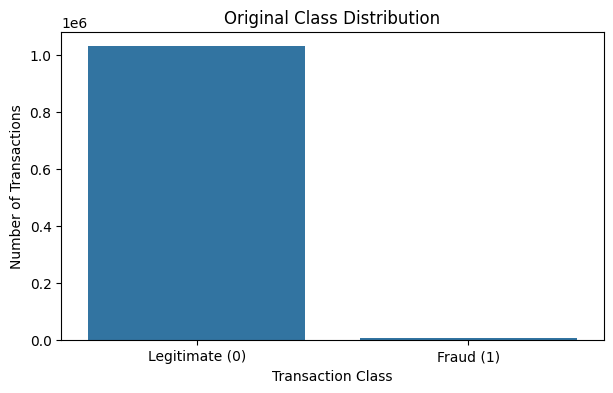

In [7]:
plt.figure(figsize=(7, 4))

sns.countplot(x=y_train)

plt.title("Original Class Distribution")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.xticks([0, 1], ["Legitimate (0)", "Fraud (1)"])
plt.show()

In [8]:
smote = SMOTE(
    sampling_strategy=0.1,
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed,
    y_train
)

print("After SMOTE:")
print("Features Shape:", X_train_smote.shape)

display(y_train_smote.value_counts())

After SMOTE:
Features Shape: (1134468, 1258)


is_fraud
0    1031335
1     103133
Name: count, dtype: int64

In [9]:
under_sampler = RandomUnderSampler(
    sampling_strategy=0.1,
    random_state=42
)

X_train_under, y_train_under = under_sampler.fit_resample(
    X_train_processed,
    y_train
)

print("After Random Undersampling:")
print("Features Shape:", X_train_under.shape)

display(y_train_under.value_counts())

After Random Undersampling:
Features Shape: (66055, 1258)


is_fraud
0    60050
1     6005
Name: count, dtype: int64

In [10]:
over_sampler = RandomOverSampler(
    sampling_strategy=0.1,
    random_state=42
)

X_train_over, y_train_over = over_sampler.fit_resample(
    X_train_processed,
    y_train
)

print("After Random Oversampling:")
print("Features Shape:", X_train_over.shape)

display(y_train_over.value_counts())

After Random Oversampling:
Features Shape: (1134468, 1258)


is_fraud
0    1031335
1     103133
Name: count, dtype: int64

In [11]:
distribution = pd.DataFrame({
    "Original": y_train.value_counts(),
    "SMOTE": y_train_smote.value_counts(),
    "Undersampling": y_train_under.value_counts(),
    "Oversampling": y_train_over.value_counts()
})

display(distribution)

,Original,SMOTE,Undersampling,Oversampling
is_fraud,,,,
0,1031335,1031335,60050,1031335
1,6005,103133,6005,103133


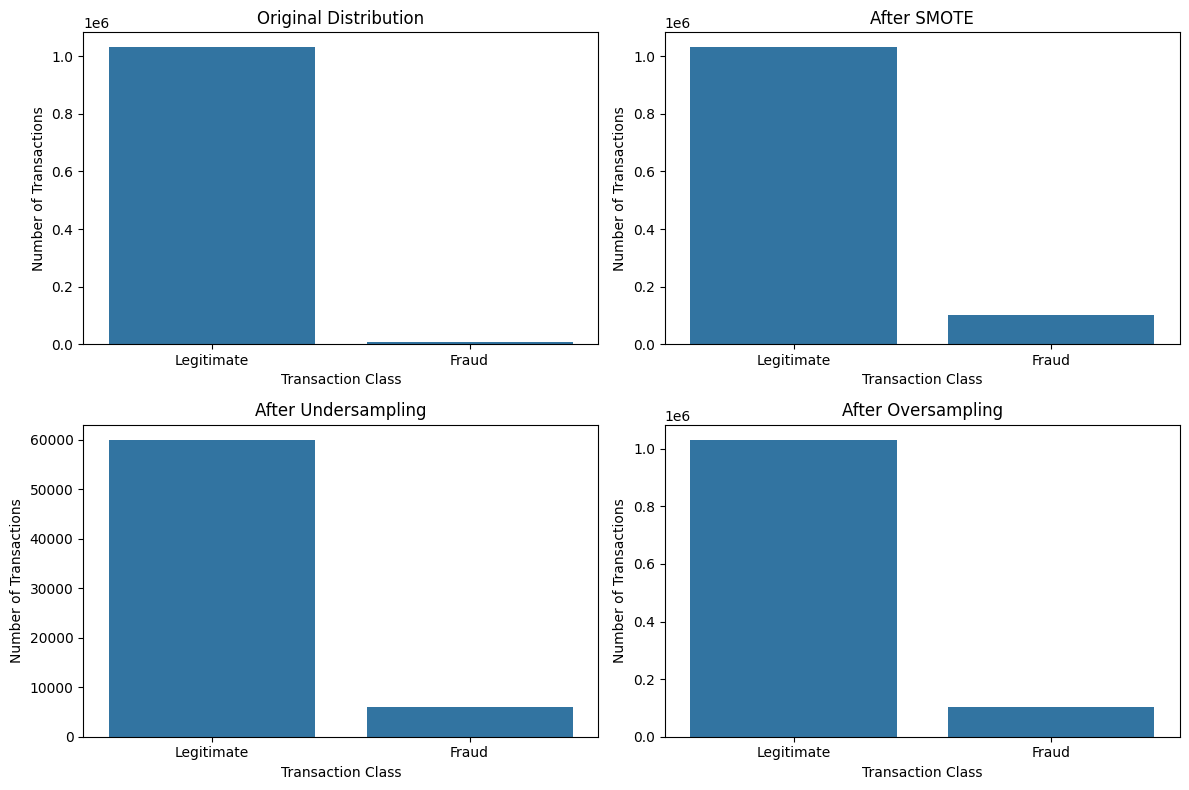

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

datasets = [
    (y_train, "Original Distribution"),
    (y_train_smote, "After SMOTE"),
    (y_train_under, "After Undersampling"),
    (y_train_over, "After Oversampling")
]

for ax, (target, title) in zip(axes.flatten(), datasets):

    sns.countplot(x=target, ax=ax)

    ax.set_title(title)
    ax.set_xlabel("Transaction Class")
    ax.set_ylabel("Number of Transactions")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Legitimate", "Fraud"])

plt.tight_layout()
plt.show()

In [14]:
os.makedirs("processed_data/imbalance", exist_ok=True)

# Save SMOTE
save_npz(
    "processed_data/imbalance/X_train_smote.npz",
    X_train_smote
)
y_train_smote.to_csv(
    "processed_data/imbalance/y_train_smote.csv",
    index=False
)

# Save undersampling
save_npz(
    "processed_data/imbalance/X_train_under.npz",
    X_train_under
)
y_train_under.to_csv(
    "processed_data/imbalance/y_train_under.csv",
    index=False
)

# Save oversampling
save_npz(
    "processed_data/imbalance/X_train_over.npz",
    X_train_over
)
y_train_over.to_csv(
    "processed_data/imbalance/y_train_over.csv",
    index=False
)

print("All resampled datasets saved successfully!")

All resampled datasets saved successfully!


In [15]:
print("Validation Shape:", X_val_processed.shape)
print("Testing Shape:", X_test_processed.shape)

print("\nValidation Distribution:")
display(y_val.value_counts())

print("\nTesting Distribution:")
display(y_test.value_counts())

Validation Shape: (259335, 1258)
Testing Shape: (555719, 1258)

Validation Distribution:


is_fraud
0    257834
1      1501
Name: count, dtype: int64


Testing Distribution:


is_fraud
0    553574
1      2145
Name: count, dtype: int64